# What does Γ change, and what does it leave unspecified?

This notebook separates three controls in an observational-data plus randomized-trial simulation: **hidden selection**, **hidden outcome dependence**, and **outcome differences between sources**. The figures show exact structural truth, so changes in these controls can be understood before comparing estimators.

By the end you can construct an MSM-compatible assignment law, check it against an independent Bayes calculation, inspect Γ(X), and generate role-separated data. This is an original DGP construction, not a reproduction of a published empirical result or a performance leaderboard.


## Before running

Use a Python environment with this repository installed and its notebook dependencies available: NumPy, Matplotlib, and IPython. The notebook does not install packages, download data, or read repository-relative files; it works from any working directory once the package is installed.

Run the cells in order. Editable controls are collected below. The examples use small samples and exact two-point sums, with no model fitting or parameter search. Stored outputs show the executed defaults; use **Restart Kernel and Run All** after changing controls.


In [1]:
%matplotlib inline
from fractions import Fraction

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from obs_rct_benchmark.sensitivity import (
    GammaDGPConfig,
    construct_msm_propensities,
    gamma_truth_at,
    generate_gamma_problem,
    msm_propensity_bounds,
    msm_truth_at,
    sample_msm_source,
)

# Editable controls for the profile figures and generated problem.
SEED = 2026
GAMMA_MIN = 1.0
GAMMA_MAX = 4.0
GAMMA_SLOPE = 1.2
OBSERVED_OVERLAP = 0.7
HIDDEN_LOADING_0 = 0.5
HIDDEN_LOADING_1 = 1.0
OBS_BASELINE_SHIFT = 0.2
OBS_CATE_SHIFT = 0.6
BIAS_DIRECTION = 1  # +1 or -1

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(str(v).replace("|", r"\|") for v in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


## 1. The assignment law and the target

Here U is independent of X and is equally likely to be −1 or +1. Write e(x) = P(T = 1 | X = x), and p(x,u) = P(T = 1 | X = x,U = u). The marginal sensitivity model constrains

\[
\frac{1}{\Gamma(x)} \leq
\frac{p(x,u)/(1-p(x,u))}{e(x)/(1-e(x))}
\leq \Gamma(x).
\]

The factory preserves e(x) by setting p(x,±1) = e(x) ± d δ(x), with direction d ∈ {−1,+1}. If ℓ and h are the MSM propensity endpoints, δ = min(e−ℓ, h−e). Thus (p(x,−1)+p(x,+1))/2 = e(x), and at least one hidden branch attains the specified bound in real arithmetic. The implementation rejects numerically unrepresentable contrasts rather than silently weakening them.

Target/RCT outcomes obey Y(t) = μ₀(X) + t τ(X) + aₜ(X) U + noise. OBS additionally has arm shift sₜ(X). Because E[U | X] = 0, the **target CATE** is τ(X). The OBS regression contrast differs from it by a hidden-selection component plus s₁−s₀.

This Γ compares full versus marginal treatment odds. It is not a bound directly on outcome bias, and it is not a pairwise hidden-odds parameter. See [Zhao, Small and Bhattacharya (2019)](https://doi.org/10.1111/rssb.12327) for the marginal sensitivity model; this notebook's binary-U factory is a separate, original construction.


## 2. An independent rational Bayes check

Fix e = 1/2 and Γ = 3. The two assignment probabilities are p(−1) = 1/4 and p(+1) = 3/4. Therefore P(U = +1 | T = 1) = 3/4, E[U | T = 1] = 1/2, and E[U | T = 0] = −1/2.

With a₀ = 1/2 and a₁ = 3/2, the two arm regression biases are −1/4 and 3/4. The confounding contribution to the CATE contrast is therefore 1. Set τ = 2, s₀ = 1/5, and s₁ = 9/10: the source CATE shift is 7/10, and the OBS regression contrast is 37/10.

The following calculation uses exact rational arithmetic and explicit Bayes sums, independently of the factory's truth equations. Only the final assertions compare the result with the public API.


In [2]:
e = Fraction(1, 2)
g = Fraction(3)
p_minus = e / (g * (1 - e) + e)
p_plus = g * e / (1 - e + g * e)
assert (p_minus + p_plus) / 2 == e

# Enumerate the two hidden states, then apply Bayes' rule exactly.
hidden = [(-1, p_minus), (1, p_plus)]
mass_treated = sum(Fraction(1, 2) * p for u, p in hidden)
mass_control = sum(Fraction(1, 2) * (1 - p) for u, p in hidden)
mean_u1 = sum(Fraction(1, 2) * u * p for u, p in hidden) / mass_treated
mean_u0 = sum(Fraction(1, 2) * u * (1 - p) for u, p in hidden) / mass_control
bias0, bias1 = Fraction(1, 2) * mean_u0, Fraction(3, 2) * mean_u1
source_shift = Fraction(9, 10) - Fraction(1, 5)
obs_contrast = Fraction(2) + bias1 - bias0 + source_shift
assert (bias0, bias1, obs_contrast) == (Fraction(-1, 4), Fraction(3, 4), Fraction(37, 10))

rational_truth = msm_truth_at(
    np.zeros((1, 2)), observed_propensity=float(e), gamma=float(g),
    mu0=0.0, tau=2.0, hidden_loading0=0.5, hidden_loading1=1.5,
    obs_shift0=0.2, obs_shift1=0.9,
)
np.testing.assert_allclose(rational_truth["confounding_bias_0"], float(bias0))
np.testing.assert_allclose(rational_truth["confounding_bias_1"], float(bias1))
np.testing.assert_allclose(
    rational_truth["obs_conditional_mean_1"] - rational_truth["obs_conditional_mean_0"],
    float(obs_contrast),
)
show_table(["Quantity", "Independent exact value"], [
    ("P(T=1 | U=-1)", p_minus), ("P(T=1 | U=+1)", p_plus),
    ("E[U | T=1]", mean_u1), ("E[U | T=0]", mean_u0),
    ("Confounding CATE bias", bias1 - bias0),
    ("OBS source CATE shift", source_shift), ("OBS regression contrast", obs_contrast),
])


| Quantity | Independent exact value |
| --- | --- |
| P(T=1 \| U=-1) | 1/4 |
| P(T=1 \| U=+1) | 3/4 |
| E[U \| T=1] | 1/2 |
| E[U \| T=0] | -1/2 |
| Confounding CATE bias | 1 |
| OBS source CATE shift | 7/10 |
| OBS regression contrast | 37/10 |

## 3. Three controls, three different questions

| Control | What it changes in this factory | What it does not determine |
| --- | --- | --- |
| Γ(X) | Separation between hidden treatment-assignment branches at fixed e(X) | Outcome dependence on U or cross-source outcome shifts |
| a₀(X), a₁(X) | How U enters each potential outcome | The assignment law |
| s₀(X), s₁(X) | OBS outcome differences from the target/RCT population | Hidden treatment selection |

Two negative controls are useful. **Γ = 1** removes hidden treatment selection here, but an OBS source shift may remain. **Γ > 1 with a₀ = a₁ = 0** creates hidden selection without confounding bias in outcomes. Neither case alone establishes that pooling sources is valid: outcome shifts can still make it invalid.


In [3]:
# Fixed teaching cases, separate from the editable profile controls above.
cases = [
    ("No hidden selection", 1.0, 1.0, 0.0),
    ("Source shift only", 1.0, 1.0, 0.7),
    ("Hidden selection; no outcome loading", 3.0, 0.0, 0.0),
    ("Selection + outcome loading + shift", 3.0, 1.0, 0.7),
]
case_rows = []
for label, gamma_value, loading, shift in cases:
    truth = msm_truth_at(
        np.zeros((1, 2)), observed_propensity=0.5, gamma=gamma_value,
        tau=2.0, hidden_loading0=loading, hidden_loading1=loading,
        obs_shift0=0.0, obs_shift1=shift,
    )
    hidden_bias = float(truth["confounding_cate_bias"][0])
    source_bias = float(truth["source_cate_shift"][0])
    if gamma_value == 1.0 or loading == 0.0:
        np.testing.assert_allclose(hidden_bias, 0.0, atol=1e-14)
    case_rows.append((label, gamma_value, loading, f"{hidden_bias:.2f}",
                      f"{source_bias:.2f}", f"{hidden_bias + source_bias:.2f}"))
show_table(["Case", "Γ", "a₀ = a₁", "Hidden CATE bias", "Source CATE shift",
            "OBS contrast − target CATE"], case_rows)


| Case | Γ | a₀ = a₁ | Hidden CATE bias | Source CATE shift | OBS contrast − target CATE |
| --- | --- | --- | --- | --- | --- |
| No hidden selection | 1.0 | 1.0 | 0.00 | 0.00 | 0.00 |
| Source shift only | 1.0 | 1.0 | 0.00 | 0.70 | 0.70 |
| Hidden selection; no outcome loading | 3.0 | 0.0 | 0.00 | 0.00 | 0.00 |
| Selection + outcome loading + shift | 3.0 | 1.0 | 1.00 | 0.70 | 1.70 |

## 4. A serializable Γ(X) profile

The built-in logistic profile has

\[
\Gamma(x)=\Gamma_{\min}+(\Gamma_{\max}-\Gamma_{\min})\operatorname{expit}(b+w x_1).
\]

Its declared upper bound holds for every finite X, not just sampled rows. The Gaussian factory also controls observed overlap, sample budgets, source covariate shifts, outcome loadings, and OBS outcome shifts separately. Here all source covariate shifts are zero, so the next figures isolate assignment and outcome mechanisms. The observed propensity is `floor + (1-2*floor)*expit(observed_overlap*x1)`. Increasing the nonnegative `observed_overlap` makes treatment probabilities more separated across x1 and weakens marginal treatment-arm overlap; it does not control RCT-versus-target covariate coverage.

The horizontal axis is an **evaluation slice**: x₁ varies, while x₂ is fixed at zero. It is not an estimate of E[τ(X) | X₁], and no averaging over X₂ is implied.


In [4]:
config = GammaDGPConfig(
    name="notebook_gamma_profile", d=2,
    n_obs=160, n_rct_train=80, n_rct_tune=40, n_rct_test=40, n_eval=160,
    gamma_profile="logistic", gamma=GAMMA_MAX, gamma_min=GAMMA_MIN,
    gamma_slope=GAMMA_SLOPE, gamma_intercept=0.0,
    observed_overlap=OBSERVED_OVERLAP,
    hidden_loading0=HIDDEN_LOADING_0, hidden_loading1=HIDDEN_LOADING_1,
    obs_baseline_shift=OBS_BASELINE_SHIFT, obs_cate_shift=OBS_CATE_SHIFT,
    bias_direction=BIAS_DIRECTION,
    cate_complexity="smooth", noise_std=1.0,
)
x1 = np.linspace(-3.0, 3.0, 181)
X_slice = np.column_stack([x1, np.zeros_like(x1)])
profile_truth = gamma_truth_at(X_slice, config)

# Verify both marginal compatibility and the finite-row MSM endpoints.
branches = construct_msm_propensities(
    profile_truth["obs_propensity"], profile_truth["gamma_requested"],
    bias_direction=BIAS_DIRECTION,
)
lower, upper = msm_propensity_bounds(branches.observed, branches.gamma)
np.testing.assert_allclose((branches.p_minus + branches.p_plus) / 2, branches.observed)
np.testing.assert_array_less(lower - 1e-12, np.minimum(branches.p_minus, branches.p_plus))
np.testing.assert_array_less(np.maximum(branches.p_minus, branches.p_plus), upper + 1e-12)
np.testing.assert_allclose(branches.local_gamma, branches.gamma)


The panels distinguish the requested bound from the observed propensity, then separate the resulting arm biases from source outcome shifts. The last panel is an identity:

**OBS regression contrast − target CATE = confounding CATE bias + source CATE shift.**

Every curve below is an evaluator-only quantity from the known DGP. An estimator should never receive these arrays, U, or the full OBS propensity.


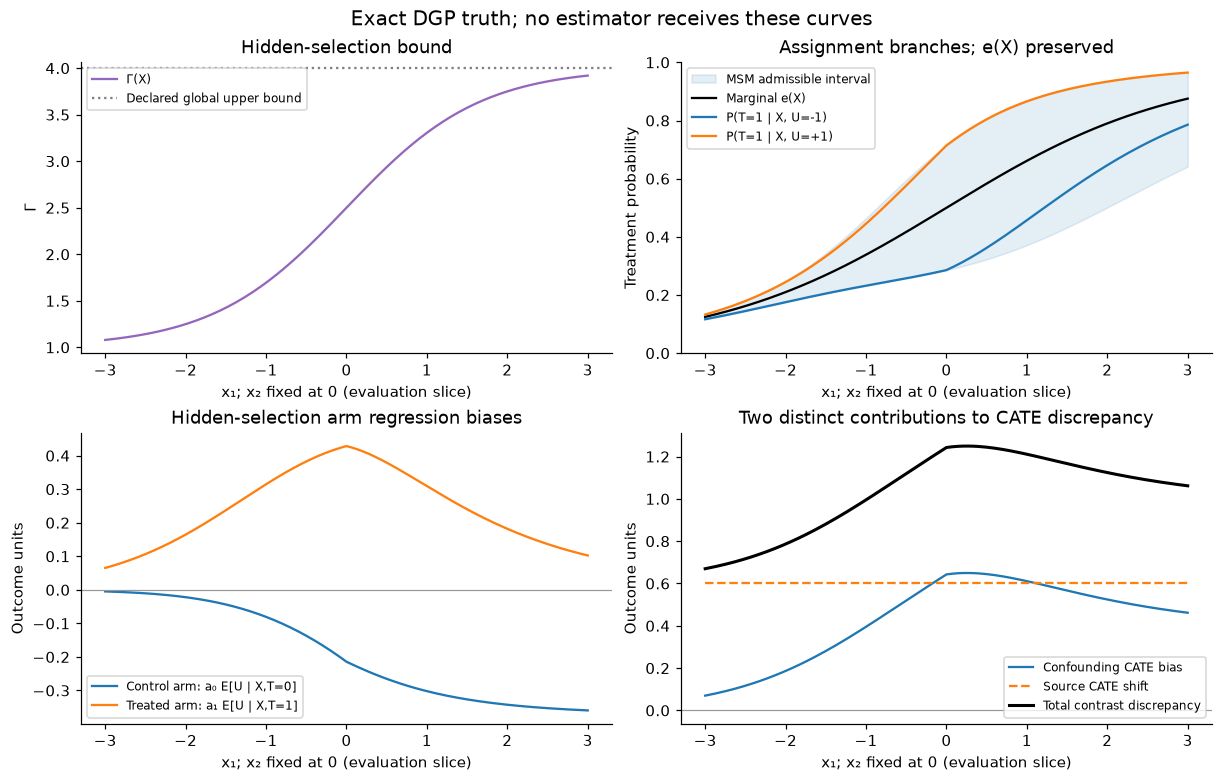

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
ax = axes[0, 0]
ax.plot(x1, profile_truth["gamma_requested"], label="Γ(X)", color="tab:purple")
ax.axhline(GAMMA_MAX, color="0.5", ls=":", label="Declared global upper bound")
ax.set(title="Hidden-selection bound", ylabel="Γ")
ax.legend(fontsize=8)

ax = axes[0, 1]
ax.fill_between(x1, lower, upper, alpha=0.12, color="tab:blue", label="MSM admissible interval")
ax.plot(x1, branches.observed, color="black", label="Marginal e(X)")
ax.plot(x1, branches.p_minus, label="P(T=1 | X, U=-1)")
ax.plot(x1, branches.p_plus, label="P(T=1 | X, U=+1)")
ax.set(title="Assignment branches; e(X) preserved", ylabel="Treatment probability", ylim=(0, 1))
ax.legend(fontsize=8)

ax = axes[1, 0]
ax.plot(x1, profile_truth["confounding_bias_0"], label="Control arm: a₀ E[U | X,T=0]")
ax.plot(x1, profile_truth["confounding_bias_1"], label="Treated arm: a₁ E[U | X,T=1]")
ax.axhline(0, color="0.6", lw=0.8)
ax.set(title="Hidden-selection arm regression biases", ylabel="Outcome units")
ax.legend(fontsize=8)

ax = axes[1, 1]
confounding = profile_truth["confounding_cate_bias"]
source_shift = profile_truth["source_cate_shift"]
contrast_error = (profile_truth["obs_conditional_mean_1"]
                  - profile_truth["obs_conditional_mean_0"]
                  - profile_truth["tau_target"])
np.testing.assert_allclose(contrast_error, confounding + source_shift, atol=1e-12)
ax.plot(x1, confounding, label="Confounding CATE bias")
ax.plot(x1, source_shift, label="Source CATE shift", ls="--")
ax.plot(x1, contrast_error, label="Total contrast discrepancy", color="black", lw=2)
ax.axhline(0, color="0.6", lw=0.8)
ax.set(title="Two distinct contributions to CATE discrepancy", ylabel="Outcome units")
ax.legend(fontsize=8)
for ax in axes.flat:
    ax.set_xlabel("x₁; x₂ fixed at 0 (evaluation slice)")
fig.suptitle("Exact DGP truth; no estimator receives these curves", fontsize=13)
plt.show()


## 5. Γ is not an outcome-bias scale

At e = 1/2, increasing Γ changes the hidden assignment branches. It creates no outcome confounding when both loadings are zero. Different loadings can also produce very different biases at the same Γ. The next curves hold all other quantities fixed and calculate exact truth, with no fitting or finite-sample randomness.

The second panel fixes Γ = 1 while changing the OBS CATE shift. It makes visible why “no hidden confounding” and “no source outcome difference” are separate assumptions in an OBS–RCT benchmark.


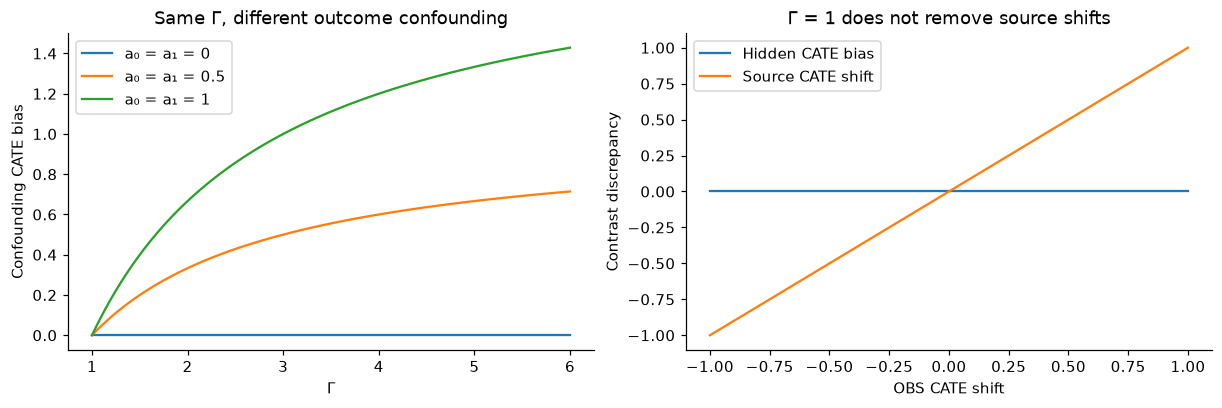

In [6]:
gamma_grid = np.linspace(1.0, 6.0, 101)
X_grid = np.column_stack([gamma_grid, np.zeros_like(gamma_grid)])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), constrained_layout=True)
for loading in (0.0, 0.5, 1.0):
    t = msm_truth_at(
        X_grid, observed_propensity=0.5, gamma=lambda X: X[:, 0],
        hidden_loading0=loading, hidden_loading1=loading,
    )
    # Independent formula for fair U, e=1/2, equal arm loadings.
    expected = 2 * loading * (gamma_grid - 1) / (gamma_grid + 1)
    np.testing.assert_allclose(t["confounding_cate_bias"], expected, atol=1e-12)
    axes[0].plot(gamma_grid, t["confounding_cate_bias"], label=f"a₀ = a₁ = {loading:g}")
axes[0].set(title="Same Γ, different outcome confounding", xlabel="Γ", ylabel="Confounding CATE bias")
axes[0].legend()

shift_grid = np.linspace(-1.0, 1.0, 81)
t_no_selection = msm_truth_at(
    np.column_stack([shift_grid, np.zeros_like(shift_grid)]), observed_propensity=0.5, gamma=1.0,
    hidden_loading0=1.0, hidden_loading1=1.0,
    obs_shift0=0.0, obs_shift1=lambda X: X[:, 0],
)
np.testing.assert_allclose(t_no_selection["confounding_cate_bias"], 0.0)
axes[1].plot(shift_grid, t_no_selection["confounding_cate_bias"], label="Hidden CATE bias")
axes[1].plot(shift_grid, t_no_selection["source_cate_shift"], label="Source CATE shift")
axes[1].set(title="Γ = 1 does not remove source shifts", xlabel="OBS CATE shift", ylabel="Contrast discrepancy")
axes[1].legend()
plt.show()


## 6. Generate a complete problem while keeping truth out of training

`generate_gamma_problem(config, seed)` creates independent random streams for OBS training, RCT training, RCT tuning, RCT testing, evaluation covariates, and optional outcome-free target-reference covariates. The target law is the factory's declared Gaussian population; source covariate shifts can be configured independently.

Only `problem.training_view()` belongs in an estimator's `fit` method. The role-separated view contains observed training data and known randomized treatment probabilities. It excludes the test outcomes, exact evaluation CATE, latent U, full OBS propensity, and structural truth plotted above.


In [7]:
problem = generate_gamma_problem(config, SEED)
training = problem.training_view()
show_table(["Estimator-visible role", "Rows", "Observed fields"], [
    ("OBS train", training.obs_train.n, "X, T, Y; no known OBS propensity"),
    ("RCT train", training.rct_train.n, "X, T, Y, known_propensity"),
    ("RCT tune", training.rct_tune.n, "X, T, Y, known_propensity"),
])
assert training.obs_train.known_propensity is None
assert not hasattr(training, "truth")
assert not hasattr(training, "eval_tau")
assert not hasattr(training, "rct_test")
assert not hasattr(training.obs_train, "U")
print("Gamma specification:", problem.metadata["gamma_specification"])
print("Declared global upper bound:", problem.metadata["gamma_global_upper"])
print("Global-bound metadata:", problem.metadata["gamma_global_upper_is_bound"])


| Estimator-visible role | Rows | Observed fields |
| --- | --- | --- |
| OBS train | 160 | X, T, Y; no known OBS propensity |
| RCT train | 80 | X, T, Y, known_propensity |
| RCT tune | 40 | X, T, Y, known_propensity |

Gamma specification: {'kind': 'config_profile', 'profile': 'logistic'}
Declared global upper bound: 4.0
Global-bound metadata: True


## 7. Arbitrary Γ(X) callbacks versus serializable profiles

The Python API also accepts a deterministic `gamma(X)` callback. This is useful for localized confounding or an existing covariate law. Callbacks must return one finite value at least 1 per row (or a scalar). They should depend on the supplied X, not mutable random state or row order.

A callback is checked at generated/evaluated rows. **The package does not infer or certify its global bound.** Even if a callback is visibly bounded to its author, its metadata records `gamma_global_upper=None` and a pointwise guarantee. Built-in constant/logistic profiles preserve a serializable global bound; use them when comparing saved CLI configurations. An arbitrary Python callback cannot be reconstructed from a TOML parameter list.


Callback specification: {'kind': 'callback', 'guarantee': 'pointwise_at_evaluated_rows'}
Callback global-bound metadata: None


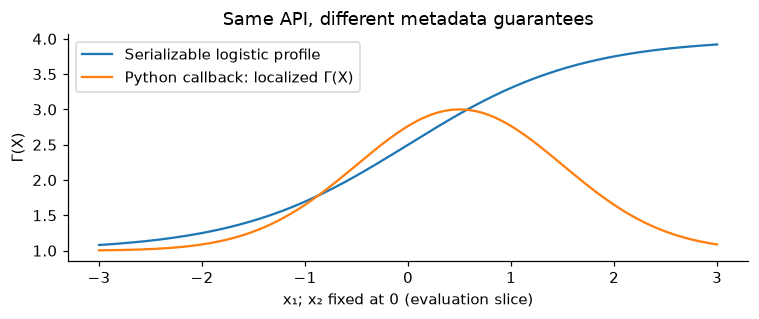

In [8]:
def localized_gamma(X):
    # Bounded by 3 by inspection of this specific formula, but the package
    # deliberately does not turn arbitrary callback code into a bound claim.
    return 1.0 + 2.0 * np.exp(-0.5 * (X[:, 0] - 0.5) ** 2)

callback_problem = generate_gamma_problem(config, SEED, gamma=localized_gamma)
callback_truth = gamma_truth_at(X_slice, config, gamma=localized_gamma)
assert callback_problem.metadata["gamma_global_upper"] is None
assert callback_problem.metadata["gamma_global_upper_is_bound"] is False
print("Callback specification:", callback_problem.metadata["gamma_specification"])
print("Callback global-bound metadata:", callback_problem.metadata["gamma_global_upper"])

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(x1, profile_truth["gamma_requested"], label="Serializable logistic profile")
ax.plot(x1, callback_truth["gamma_requested"], label="Python callback: localized Γ(X)")
ax.set(xlabel="x₁; x₂ fixed at 0 (evaluation slice)", ylabel="Γ(X)", title="Same API, different metadata guarantees")
ax.legend()
plt.tight_layout()
plt.show()


## 8. Supply your own covariate distribution

`sample_msm_source` is the lower-level interface: you supply X, assignment, outcome functions, a role, and an RNG. The returned pair contains **observed data first, evaluator truth second**. The example uses a bounded uniform covariate law and a constant e(X) = 0.4, demonstrating that the marginal propensity need not be 1/2.

It still assumes a fair binary U independent of X. General hidden distributions require a different construction that preserves the stated marginal assignment law. Merely clipping a propensity into MSM bounds would not establish marginal compatibility.


In [9]:
rng = np.random.default_rng(SEED + 1)
X_custom = rng.uniform(-2.0, 2.0, size=(120, 2))
custom_observed, custom_oracle = sample_msm_source(
    X_custom, source="obs", role="obs_train", rng=rng,
    observed_propensity=0.4, gamma=2.5,
    mu0=lambda X: X[:, 0] + 0.2 * X[:, 1],
    tau=lambda X: 1.0 + np.tanh(X[:, 0]),
    hidden_loading0=0.3, hidden_loading1=0.8,
    obs_shift0=0.0, obs_shift1=0.4, noise_std=0.5,
)
np.testing.assert_allclose(
    (custom_oracle["hidden_propensity_minus"] + custom_oracle["hidden_propensity_plus"]) / 2,
    0.4,
)
assert custom_observed.known_propensity is None
assert custom_observed.X.shape == (120, 2)
print("Observed arrays:", custom_observed.X.shape, custom_observed.T.shape, custom_observed.Y.shape)
print("Evaluator truth is a separate object:", len(custom_oracle), "named arrays")


Observed arrays: (120, 2) (120,) (120,)
Evaluator truth is a separate object: 22 named arrays


## What to vary in a benchmark

Declare the scientific contrast before inspecting results. For example, vary Γ while keeping e(X), outcome loadings, source shifts, sample sizes, and target law fixed; then vary outcome loadings in a separate comparison. If the goal is robustness to source outcome shifts, include Γ = 1 controls so this mechanism is not confused with hidden selection. A Γ comparison changes this particular assignment construction; it is not a distribution-free ordering of estimation difficulty.

When evaluating a method, choose controls without looking at its test error, fit through the training view, and report performance across independent seeds with failures and paired uncertainty. The plots here explain generator assumptions and verify exact identities; they do not show that an estimator is accurate or that a DGP is empirically realistic.

Continue with the introductory notebook for a complete estimator comparison, the empirical-data notebook for masking and finite-population truth, or [the factory documentation](https://github.com/snu-causality-lab/obs-rct-benchmark/blob/main/docs/SENSITIVITY.md) for configuration details.


In [10]:
# Compact end-to-end teaching checks: no hidden-selection bias at Γ=1,
# no outcome confounding with zero loadings, exact decomposition, safe metadata.
assert len(case_rows) == 4
assert np.isfinite(profile_truth["confounding_cate_bias"]).all()
assert np.isfinite(callback_truth["gamma_requested"]).all()
assert problem.metadata["gamma_global_upper"] == GAMMA_MAX
assert callback_problem.metadata["gamma_global_upper"] is None
print("All independent Bayes checks, decomposition checks, and information-boundary checks passed.")


All independent Bayes checks, decomposition checks, and information-boundary checks passed.
